In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.stats import entropy

sns.set_theme(style="whitegrid")

In [3]:
DATASETS = {
    "WoS46985": "WOS46985_RESULTS",
    "TREC": "TREC_RESULTS",
    "CB": "CB_RESULTS",
    "RTE": "RTE_RESULTS",
    "DBPedia": "DBPEDIA_RESULTS"
}

STRATEGIES = {
    "simple": "Simple",
    "instruct": "Detail",
    "fewshot": "1-shot"
}

results = {}

for dataset, folder in DATASETS.items():
    results[dataset] = {}

    for strategy in STRATEGIES:
        path = Path(folder) / f"results_{strategy}.json"

        with open(path, encoding="utf-8") as f:
            data = json.load(f)

        samples = {
            key: value
            for key, value in data.items()
            if isinstance(value, dict)
            and "distribution" in value
            and "target" in value
        }

        results[dataset][strategy] = samples

        print(f"{dataset:<12} {strategy:<10} {len(samples):>5} samples")

WoS46985     simple      2000 samples
WoS46985     instruct    2000 samples
WoS46985     fewshot     2000 samples
TREC         simple       500 samples
TREC         instruct     500 samples
TREC         fewshot      500 samples
CB           simple       250 samples
CB           instruct     250 samples
CB           fewshot      250 samples
RTE          simple      2490 samples
RTE          instruct    2490 samples
RTE          fewshot     2490 samples
DBPedia      simple      2000 samples
DBPedia      instruct    2000 samples
DBPedia      fewshot     2000 samples


In [4]:
sensitivity_records = []

for dataset, strategies in results.items():
    for strategy, samples in strategies.items():
        for sample_id, sample in samples.items():

            distribution = np.asarray(sample["distribution"], dtype=float)

            # normalized entropy, including the N/A category
            sensitivity = entropy(distribution) / np.log(len(distribution))

            sensitivity_records.append({
                "Dataset": dataset,
                "Strategy": STRATEGIES[strategy],
                "Sample ID": sample["id"],
                "True class": sample["target"],
                "Sensitivity": sensitivity
            })

sensitivity_df = pd.DataFrame(sensitivity_records)

print("Total observations:", len(sensitivity_df))
display(sensitivity_df.head())

Total observations: 21720


,Dataset,Strategy,Sample ID,True class,Sensitivity
0,WoS46985,Simple,23329,Biochemistry,0.156332
1,WoS46985,Simple,7103,Biochemistry,0.000000
2,WoS46985,Simple,25733,Medical Science,0.000000
3,WoS46985,Simple,9237,Computer Science,0.000000
4,WoS46985,Simple,31983,Medical Science,0.000000


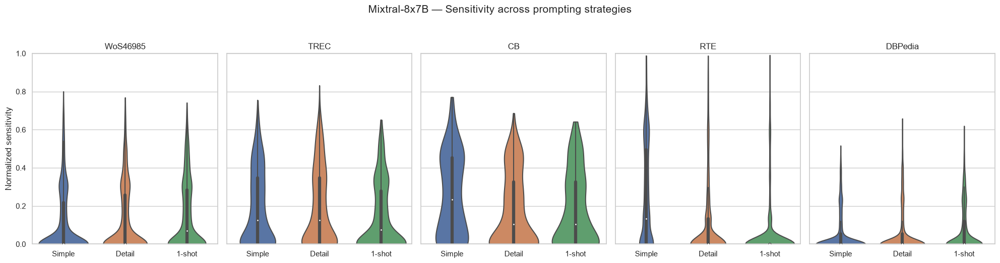

Saved sensitivity violin plots to plots/


In [9]:
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

dataset_order = ["WoS46985", "TREC", "CB", "RTE", "DBPedia"]
strategy_order = ["Simple", "Detail", "1-shot"]

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=True)

for ax, dataset in zip(axes, dataset_order):

    subset = sensitivity_df[
        sensitivity_df["Dataset"] == dataset
    ]

    sns.violinplot(
        data=subset,
        x="Strategy",
        y="Sensitivity",
        order=strategy_order,
        inner="box",
        cut=0,
        ax=ax
    )

    ax.set_title(dataset)
    ax.set_xlabel("")
    ax.set_ylabel("Normalized sensitivity" if dataset == "WoS46985" else "")
    ax.set_ylim(0, 1)

fig.suptitle(
    "Mixtral-8x7B — Sensitivity across prompting strategies",
    fontsize=15,
    y=1.04
)

plt.tight_layout()

# save before displaying
fig.savefig(
    PLOTS_DIR / "sensitivity_violin_all_datasets.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    PLOTS_DIR / "sensitivity_violin_all_datasets.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved sensitivity violin plots to plots/")

In [6]:
class_sensitivity_df = (
    sensitivity_df
    .groupby(["Dataset", "True class", "Strategy"], as_index=False)
    ["Sensitivity"]
    .mean()
)

display(class_sensitivity_df.head(10))

,Dataset,True class,Strategy,Sensitivity
0,CB,contradiction,1-shot,0.145812
1,CB,contradiction,Detail,0.208175
2,CB,contradiction,Simple,0.268046
3,CB,entailment,1-shot,0.229943
4,CB,entailment,Detail,0.142708
5,CB,entailment,Simple,0.246542
6,CB,neutral,1-shot,0.149467
7,CB,neutral,Detail,0.229079
8,CB,neutral,Simple,0.189840
9,DBPedia,Album,1-shot,0.111645


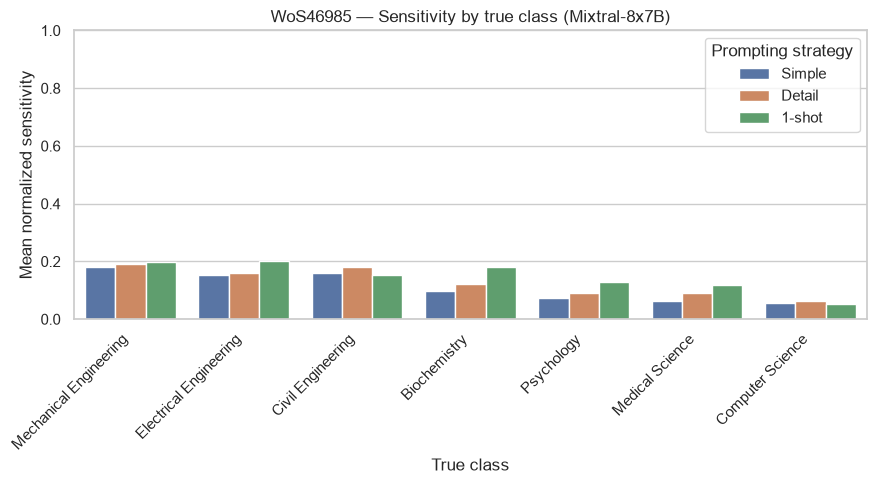

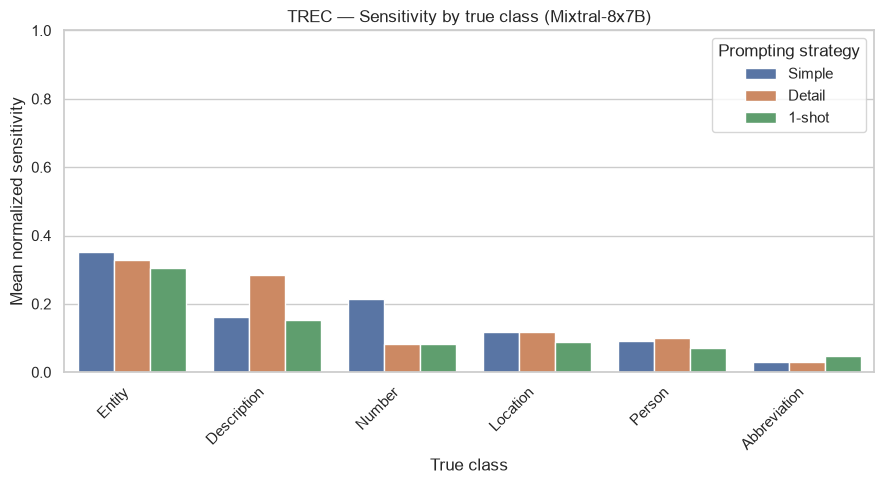

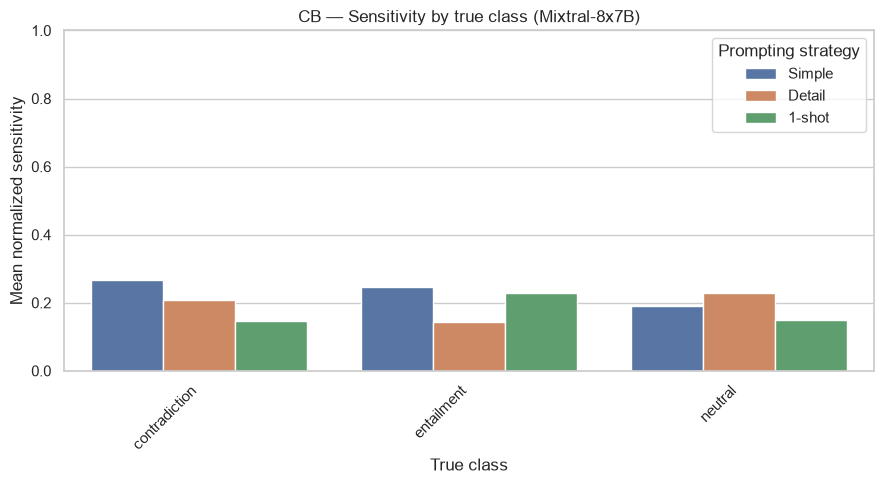

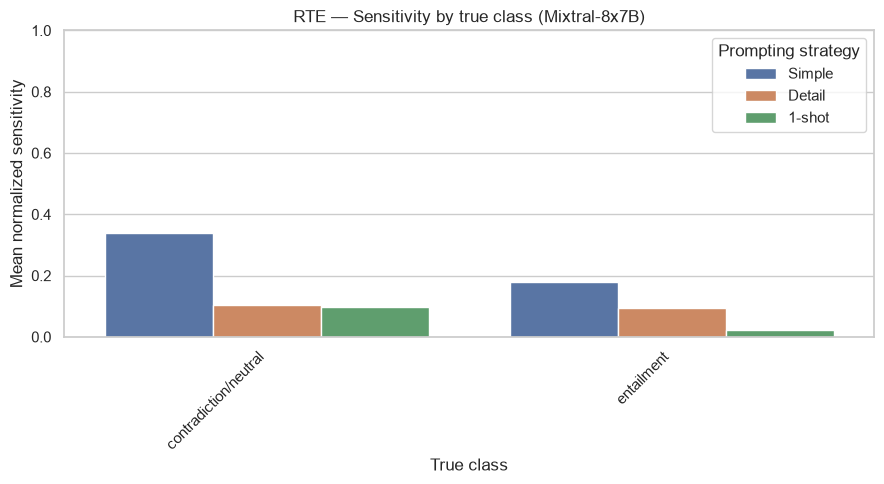

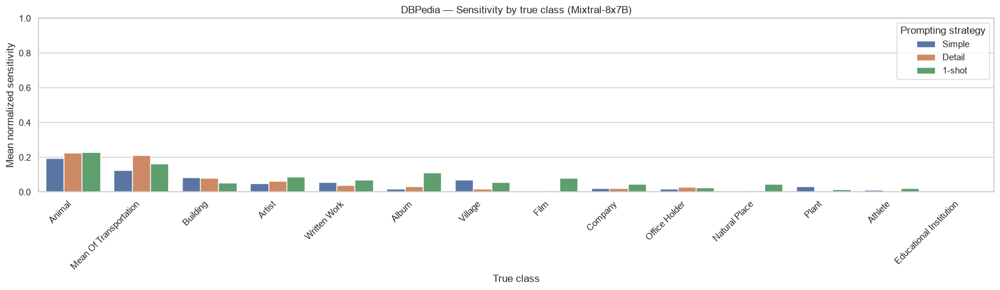

Saved all class-level sensitivity plots to plots/


In [10]:
strategy_order = ["Simple", "Detail", "1-shot"]

for dataset in dataset_order:

    subset = class_sensitivity_df[
        class_sensitivity_df["Dataset"] == dataset
    ]

    class_order = (
        subset.groupby("True class")["Sensitivity"]
        .mean()
        .sort_values(ascending=False)
        .index
    )

    fig, ax = plt.subplots(
        figsize=(max(9, len(class_order) * 1.2), 5)
    )

    sns.barplot(
        data=subset,
        x="True class",
        y="Sensitivity",
        hue="Strategy",
        hue_order=strategy_order,
        order=class_order,
        errorbar=None,
        ax=ax
    )

    ax.set_title(
        f"{dataset} — Sensitivity by true class (Mixtral-8x7B)"
    )
    ax.set_xlabel("True class")
    ax.set_ylabel("Mean normalized sensitivity")
    ax.tick_params(axis="x", labelrotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
    ax.set_ylim(0, 1)
    ax.legend(title="Prompting strategy")

    fig.tight_layout()


    filename = f"sensitivity_by_class_{dataset.lower()}"

    fig.savefig(
        PLOTS_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        PLOTS_DIR / f"{filename}.pdf",
        bbox_inches="tight"
    )

    plt.show()

print("Saved all class-level sensitivity plots to plots/")

In [11]:
consistency_records = []

for dataset, strategies in results.items():
    print(f"Processing {dataset}...")

    for strategy, samples in strategies.items():

        class_distributions = {}

        for sample in samples.values():
            target = sample["target"]
            distribution = np.asarray(
                sample["distribution"], dtype=float
            )

            class_distributions.setdefault(target, []).append(distribution)

        for target, distributions in class_distributions.items():

            P = np.asarray(distributions)
            n = len(P)

            for i in range(n):

                tvd = 0.5 * np.abs(P[i] - P).sum(axis=1)
                consistency = 1 - tvd

                consistency_records.extend({
                    "Dataset": dataset,
                    "Strategy": STRATEGIES[strategy],
                    "True class": target,
                    "Consistency": float(value)
                } for value in consistency)

consistency_df = pd.DataFrame(consistency_records)

print("Total pairwise comparisons:", len(consistency_df))
display(consistency_df.head())

Processing WoS46985...
Processing TREC...
Processing CB...
Processing RTE...
Processing DBPedia...
Total pairwise comparisons: 12109182


,Dataset,Strategy,True class,Consistency
0,WoS46985,Simple,Biochemistry,1.0
1,WoS46985,Simple,Biochemistry,0.1
2,WoS46985,Simple,Biochemistry,0.6
3,WoS46985,Simple,Biochemistry,0.6
4,WoS46985,Simple,Biochemistry,0.1


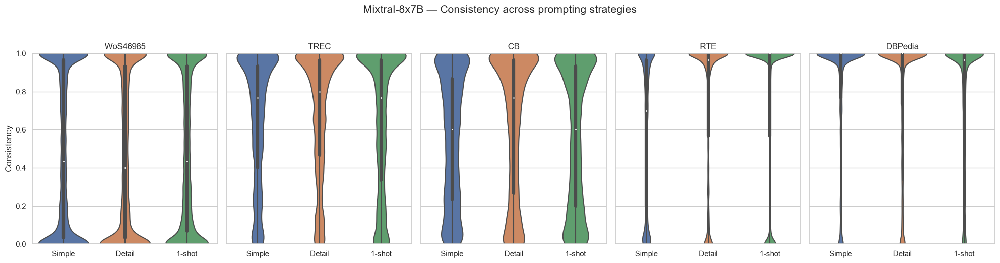

Saved consistency violin plots to plots/


In [15]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=True)

for ax, dataset in zip(axes, dataset_order):

    subset = consistency_df[
        consistency_df["Dataset"] == dataset
    ]

    sns.violinplot(
        data=subset,
        x="Strategy",
        y="Consistency",
        order=strategy_order,
        inner="box",
        cut=0,
        ax=ax
    )

    ax.set_title(dataset)
    ax.set_xlabel("")
    ax.set_ylabel(
        "Consistency" if dataset == "WoS46985" else ""
    )
    ax.set_ylim(0, 1)

fig.suptitle(
    "Mixtral-8x7B — Consistency across prompting strategies",
    fontsize=15,
    y=1.04
)

plt.tight_layout()

fig.savefig(
    PLOTS_DIR / "consistency_violin_all_datasets.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved consistency violin plots to plots/")

Processing WoS46985...


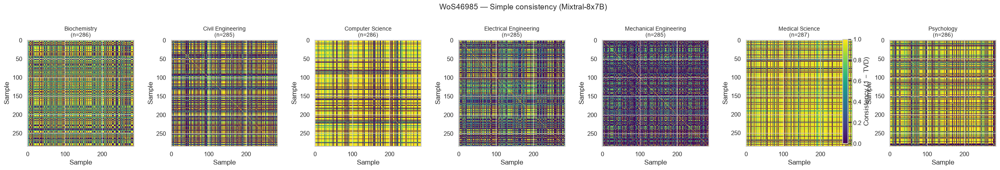

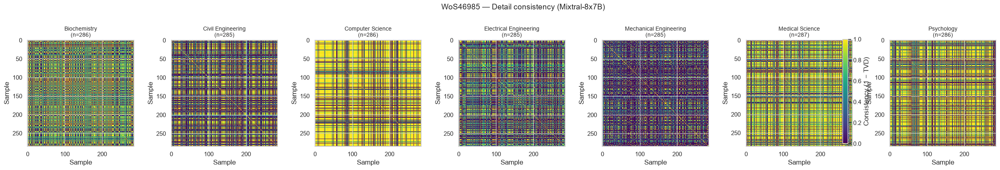

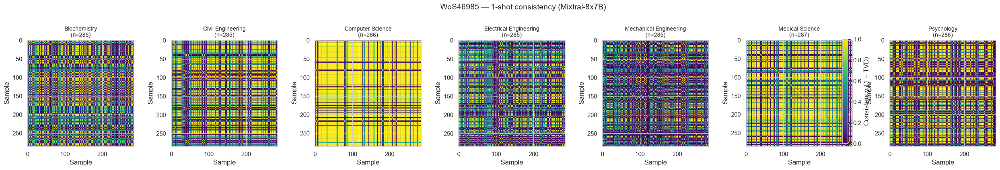

Processing TREC...


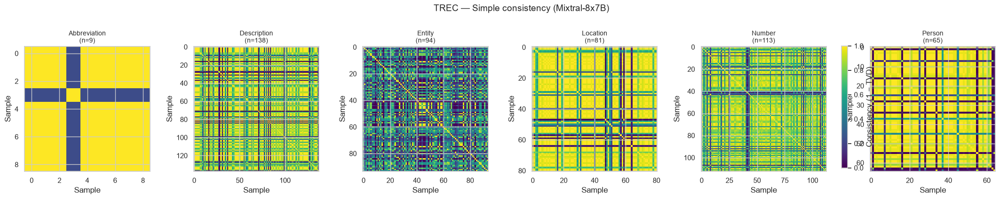

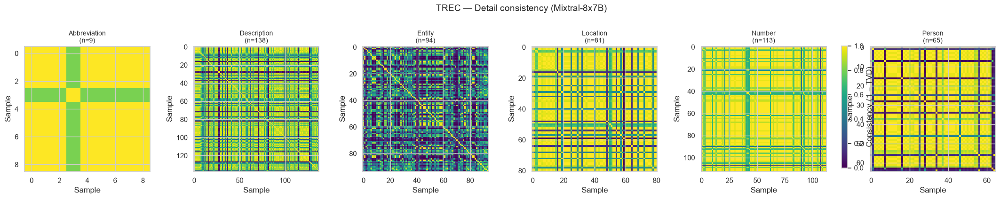

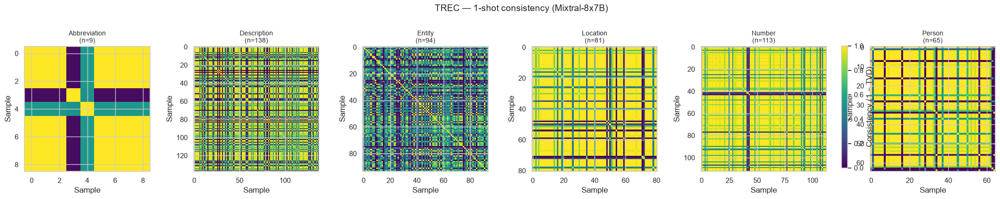

Processing CB...


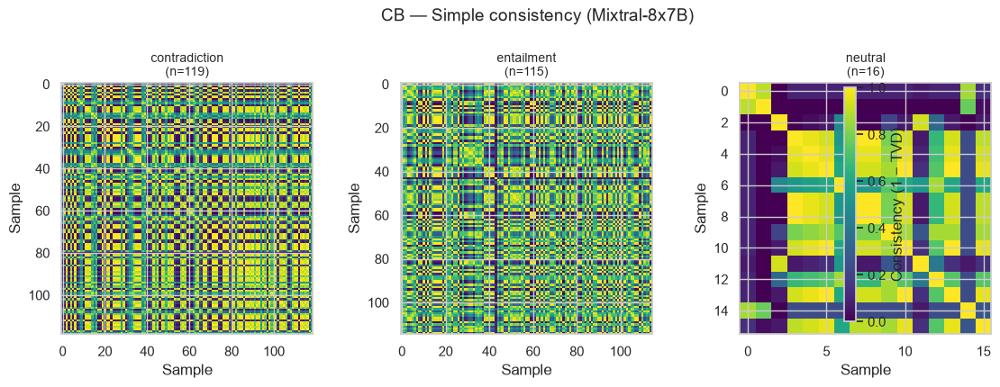

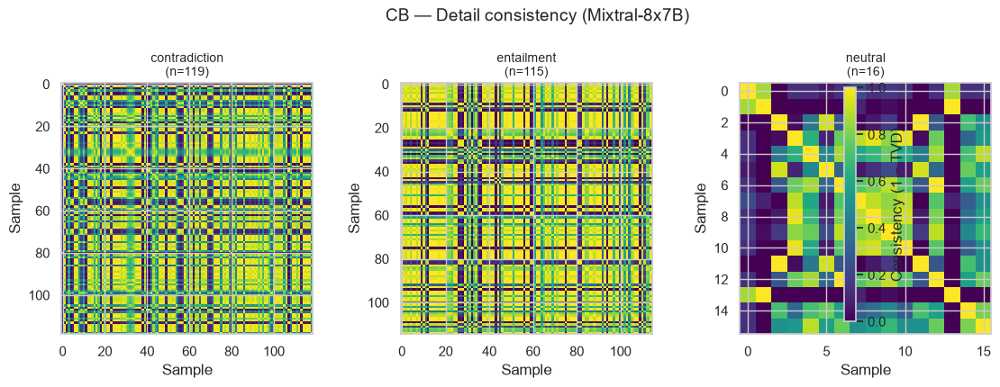

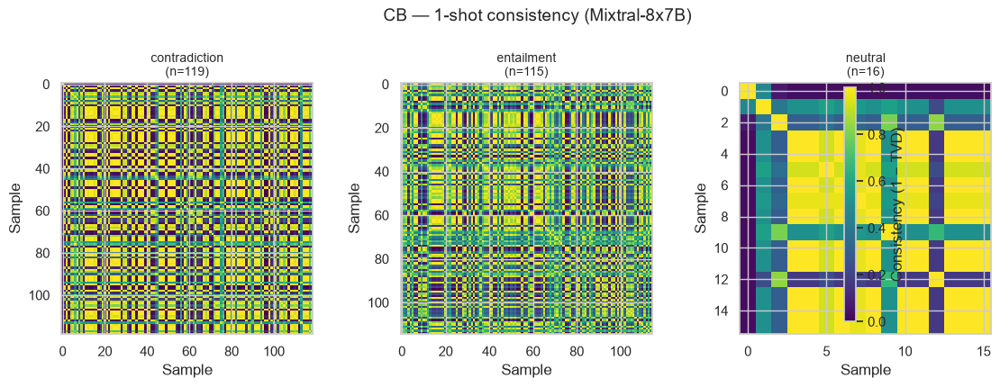

Processing RTE...


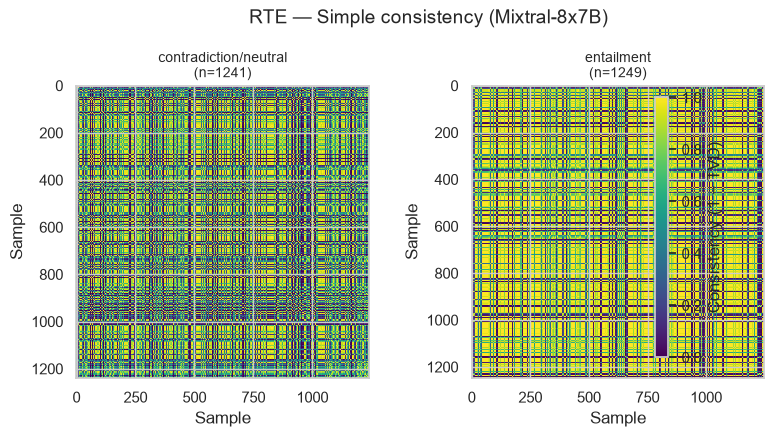

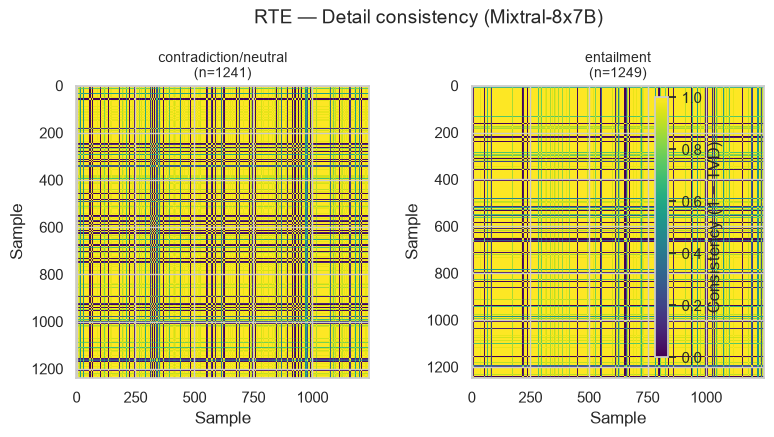

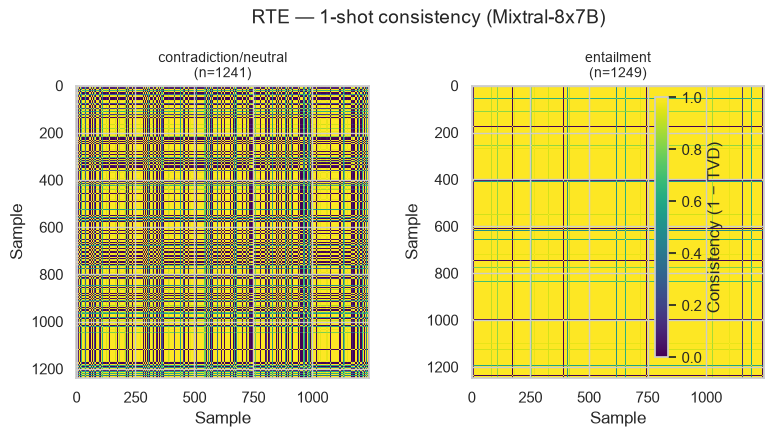

Processing DBPedia...


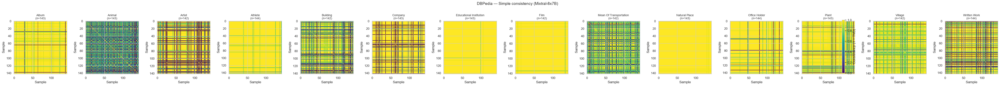

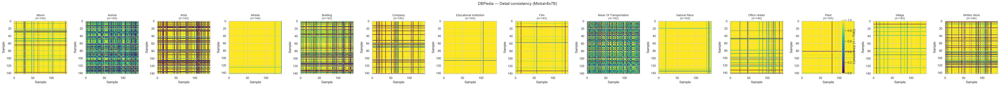

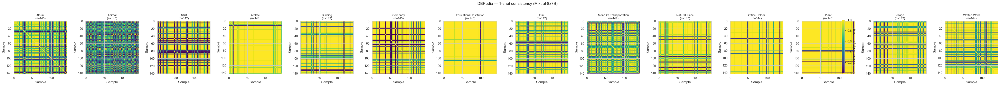

All 15 full consistency heatmap figures saved!


In [14]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import re

HEATMAP_DIR = PLOTS_DIR / "consistency_heatmaps"
HEATMAP_DIR.mkdir(parents=True, exist_ok=True)

for dataset in dataset_order:

    print(f"Processing {dataset}...")

    for strategy, strategy_label in STRATEGIES.items():

        samples = results[dataset][strategy]

        class_distributions = {}

        for sample in samples.values():
            target = sample["target"]

            distribution = np.asarray(
                sample["distribution"], dtype=np.float32
            )

            class_distributions.setdefault(
                target, []
            ).append(distribution)

        class_order = sorted(class_distributions.keys())
        n_classes = len(class_order)

        fig, axes = plt.subplots(
            1,
            n_classes,
            figsize=(max(4 * n_classes, 8), 4.5),
            squeeze=False
        )

        axes = axes.flatten()

        for ax, target in zip(axes, class_order):

            P = np.asarray(
                class_distributions[target],
                dtype=np.float32
            )

            tvd = 0.5 * np.abs(
                P[:, None, :] - P[None, :, :]
            ).sum(axis=2)

            consistency = 1 - tvd

            ax.imshow(
                consistency,
                cmap="viridis",
                vmin=0,
                vmax=1,
                origin="upper",
                interpolation="nearest",
                rasterized=True
            )

            ax.set_title(
                f"{target}\n(n={len(P)})",
                fontsize=10
            )

            ax.set_xlabel("Sample")
            ax.set_ylabel("Sample")

            del tvd, consistency

        fig.colorbar(
            ScalarMappable(
                norm=Normalize(vmin=0, vmax=1),
                cmap="viridis"
            ),
            ax=axes.tolist(),
            label="Consistency (1 − TVD)",
            shrink=0.75,
            pad=0.02
        )

        fig.suptitle(
            f"{dataset} — {strategy_label} consistency "
            f"(Mixtral-8x7B)",
            fontsize=14
        )

        fig.subplots_adjust(
            left=0.06,
            right=0.92,
            top=0.82,
            bottom=0.15,
            wspace=0.35
        )

        filename = (
            f"consistency_heatmap_"
            f"{dataset.lower()}_{strategy}"
        )

        fig.savefig(
            HEATMAP_DIR / f"{filename}.png",
            dpi=200,
            bbox_inches="tight"
        )

        fig.savefig(
            HEATMAP_DIR / f"{filename}.pdf",
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

print("All 15 full consistency heatmap figures saved!")

In [18]:
records = []

for dataset, strategies in results.items():
    for strategy, samples in strategies.items():
        for sample in samples.values():

            distribution = np.asarray(
                sample["distribution"], dtype=float
            )

            sensitivity = (
                entropy(distribution) / np.log(len(distribution))
            )

            predicted_classes = {
                prediction[0]
                for prediction in sample["info_answers"].values()
                if prediction
            }

            for predicted_class in predicted_classes:
                records.append({
                    "Dataset": dataset,
                    "Strategy": STRATEGIES[strategy],
                    "Predicted class": predicted_class,
                    "Sensitivity": sensitivity
                })

predicted_sensitivity_df = pd.DataFrame(records)

class_plot_df = (
    predicted_sensitivity_df
    .groupby(
        ["Dataset", "Strategy", "Predicted class"],
        as_index=False
    )["Sensitivity"]
    .mean()
)

display(class_plot_df.head())

,Dataset,Strategy,Predicted class,Sensitivity
0,CB,1-shot,contradiction,0.206604
1,CB,1-shot,entailment,0.258182
2,CB,1-shot,neutral,0.259475
3,CB,Detail,N/A,0.685975
4,CB,Detail,contradiction,0.228246


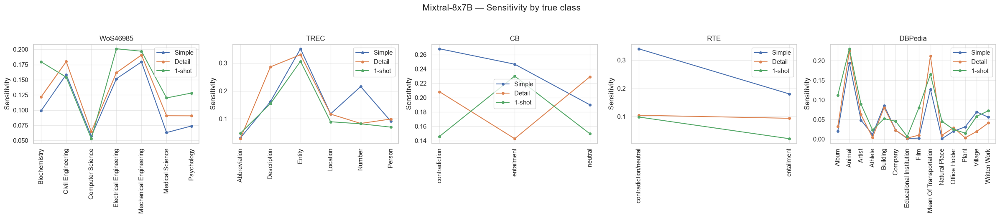

Saved to: C:\Users\cieci\OneDrive\Dokumenty\GitHub\yellow-ducks-llm-sensitivity-consistency\mixtral8x7b-Instruct-v0.1_RESULTS\plots


In [23]:
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

for ax, dataset in zip(axes, dataset_order):

    subset = class_sensitivity_df[
        class_sensitivity_df["Dataset"] == dataset
    ]

    class_order = sorted(subset["True class"].unique())

    # Plot each prompting strategy
    for strategy in strategy_order:

        strategy_data = (
            subset[subset["Strategy"] == strategy]
            .set_index("True class")
            .reindex(class_order)
        )

        ax.plot(
            class_order,
            strategy_data["Sensitivity"],
            marker="o",
            markersize=4,
            linewidth=1.5,
            label=strategy
        )

    ax.set_title(dataset)
    ax.set_xlabel("")
    ax.set_ylabel("Sensitivity")
    ax.tick_params(axis="x", labelrotation=90)
    ax.grid(True, alpha=0.4)
    ax.legend(title="")

fig.suptitle(
    "Mixtral-8x7B — Sensitivity by true class",
    fontsize=15,
    y=1.04
)

fig.tight_layout()

fig.savefig(
    PLOTS_DIR / "sensitivity_by_true_class_lines.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", PLOTS_DIR.resolve())

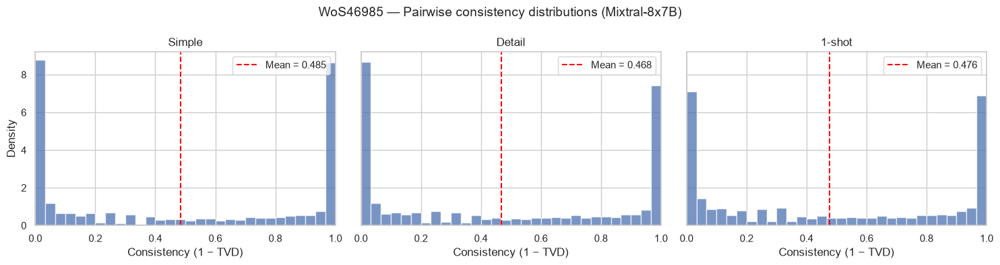

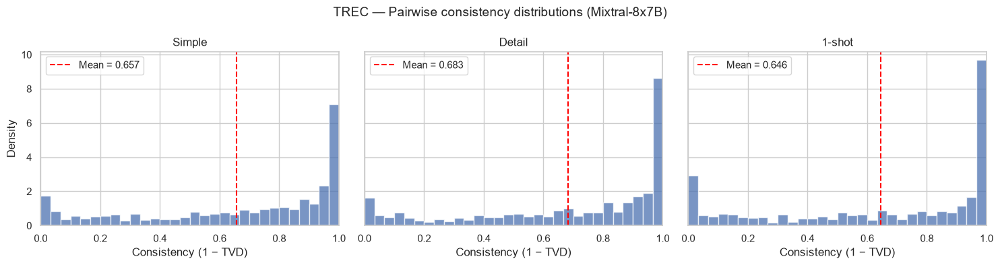

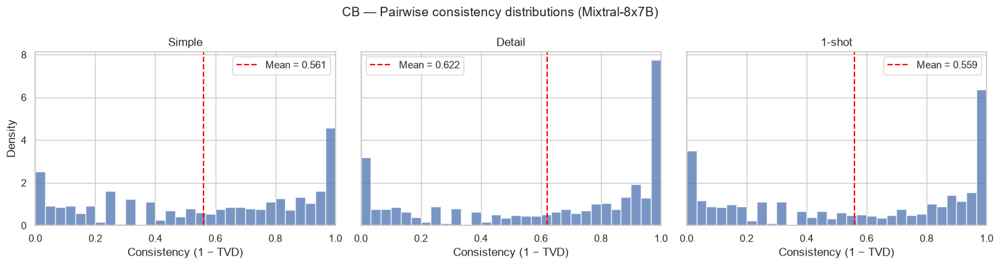

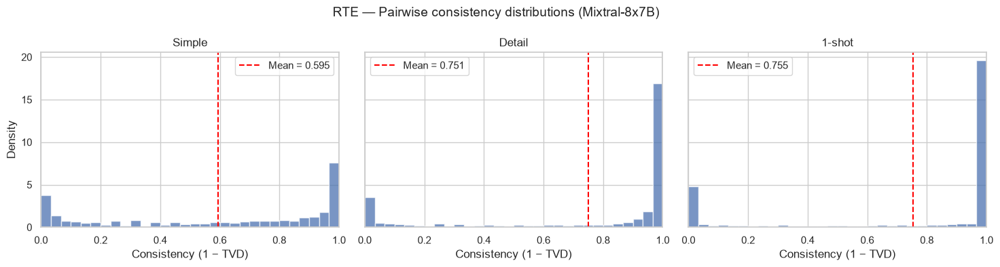

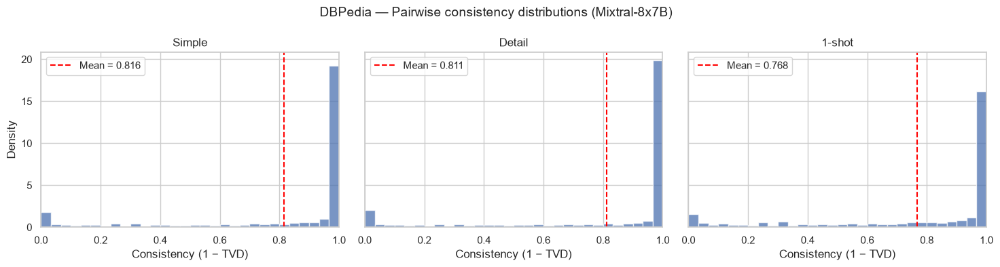

All consistency histograms saved to: C:\Users\cieci\OneDrive\Dokumenty\GitHub\yellow-ducks-llm-sensitivity-consistency\mixtral8x7b-Instruct-v0.1_RESULTS\plots\consistency_histograms


In [26]:
HIST_DIR = PLOTS_DIR / "consistency_histograms"
HIST_DIR.mkdir(parents=True, exist_ok=True)

for dataset in dataset_order:

    subset = consistency_df[
        consistency_df["Dataset"] == dataset
    ]

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4),
        sharex=True,
        sharey=True
    )

    for ax, strategy in zip(axes, strategy_order):

        values = subset.loc[
            subset["Strategy"] == strategy,
            "Consistency"
        ].to_numpy()

        ax.hist(
            values,
            bins=np.linspace(0, 1, 31),
            density=True,
            alpha=0.75,
            edgecolor="white"
        )

        mean_consistency = values.mean()

        ax.axvline(
            mean_consistency,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label=f"Mean = {mean_consistency:.3f}"
        )

        ax.set_title(strategy)
        ax.set_xlabel("Consistency (1 − TVD)")
        ax.set_xlim(0, 1)
        ax.legend()

    axes[0].set_ylabel("Density")

    fig.suptitle(
        f"{dataset} — Pairwise consistency distributions (Mixtral-8x7B)",
        fontsize=14
    )

    fig.tight_layout()

    filename = f"consistency_histogram_{dataset.lower()}"

    fig.savefig(
        HIST_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("All consistency histograms saved to:", HIST_DIR.resolve())

Processing WoS46985...


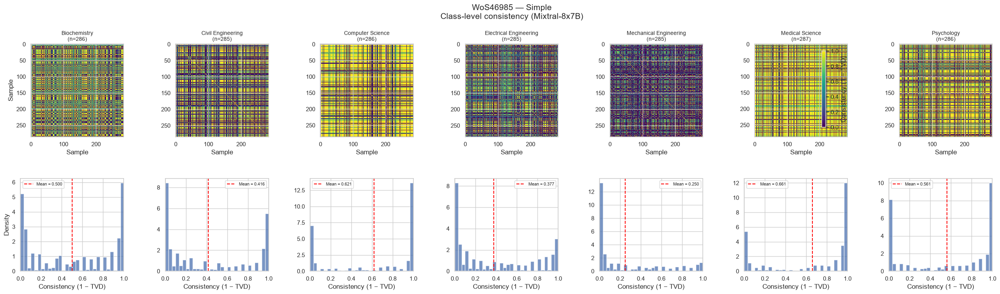

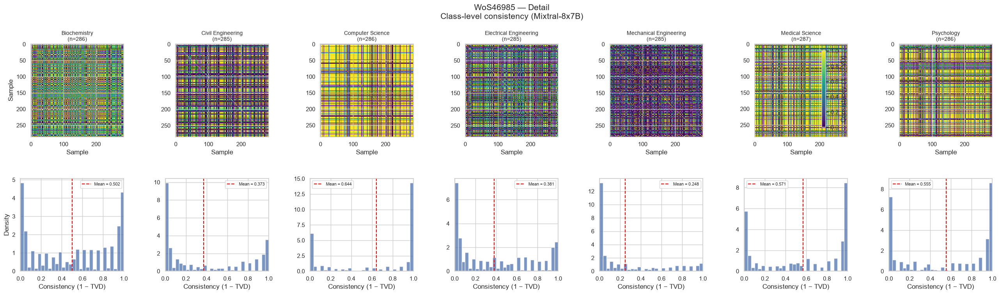

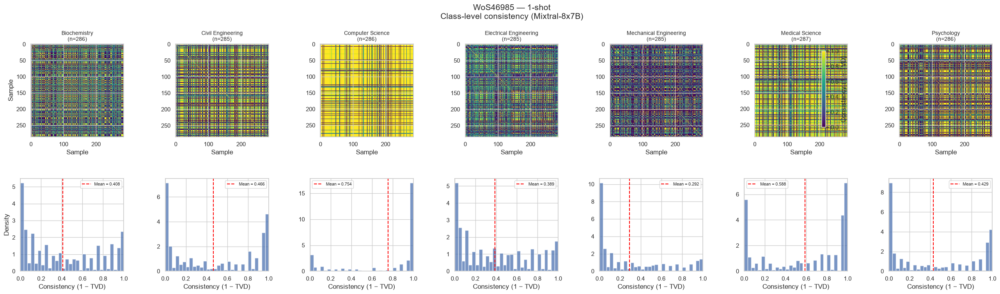

Processing TREC...


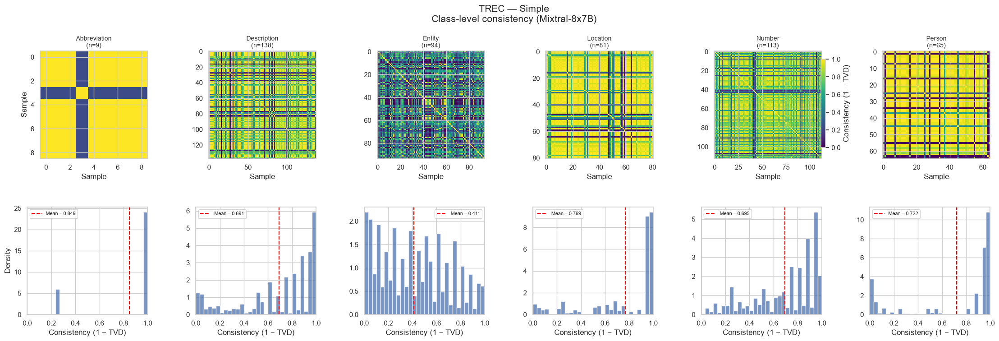

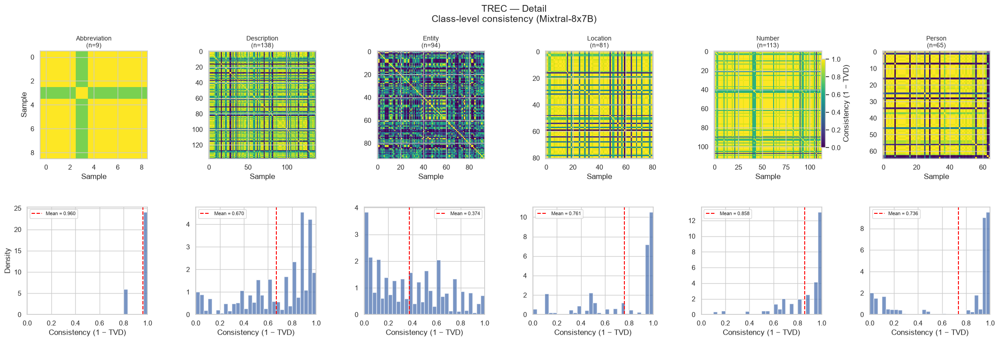

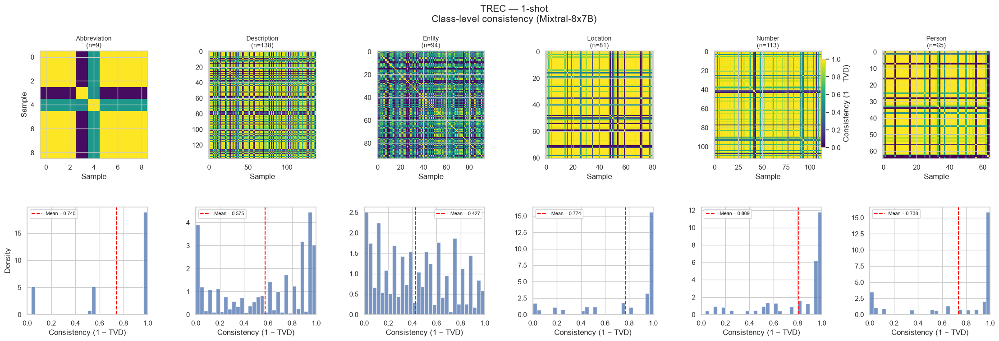

Processing CB...


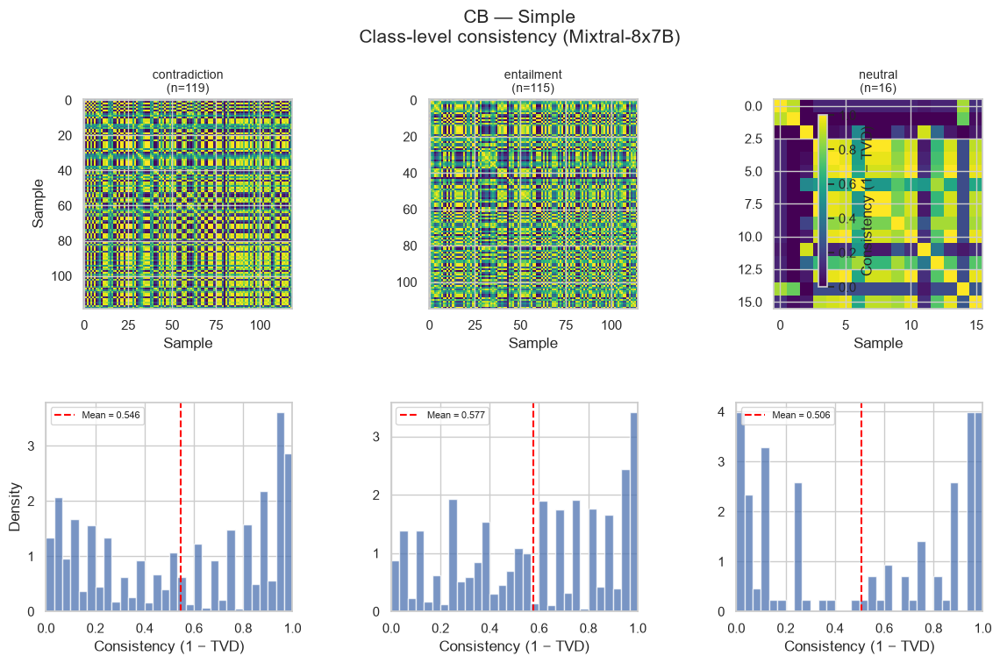

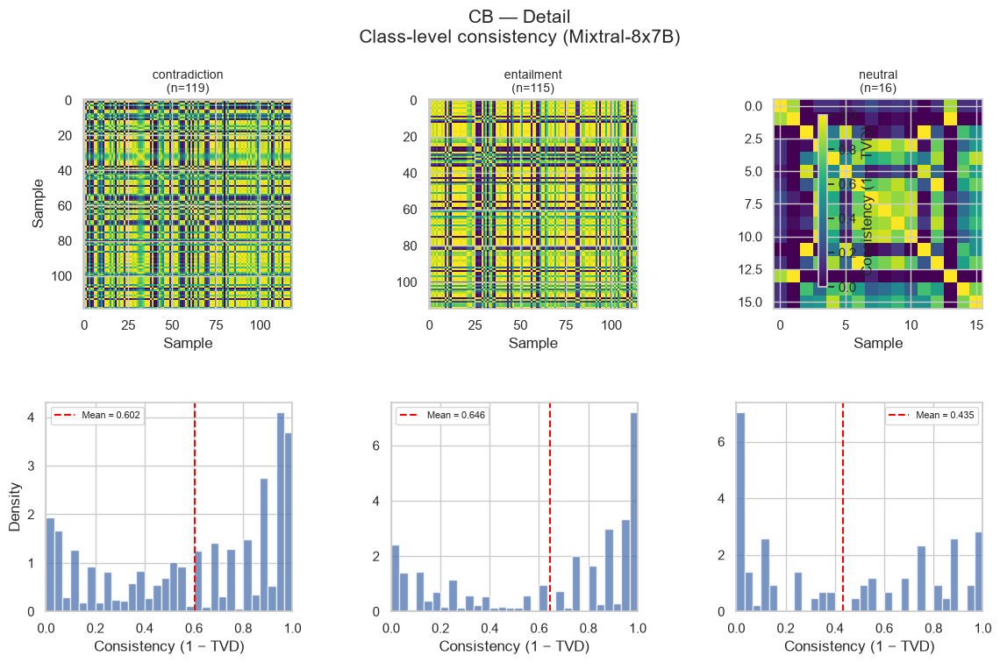

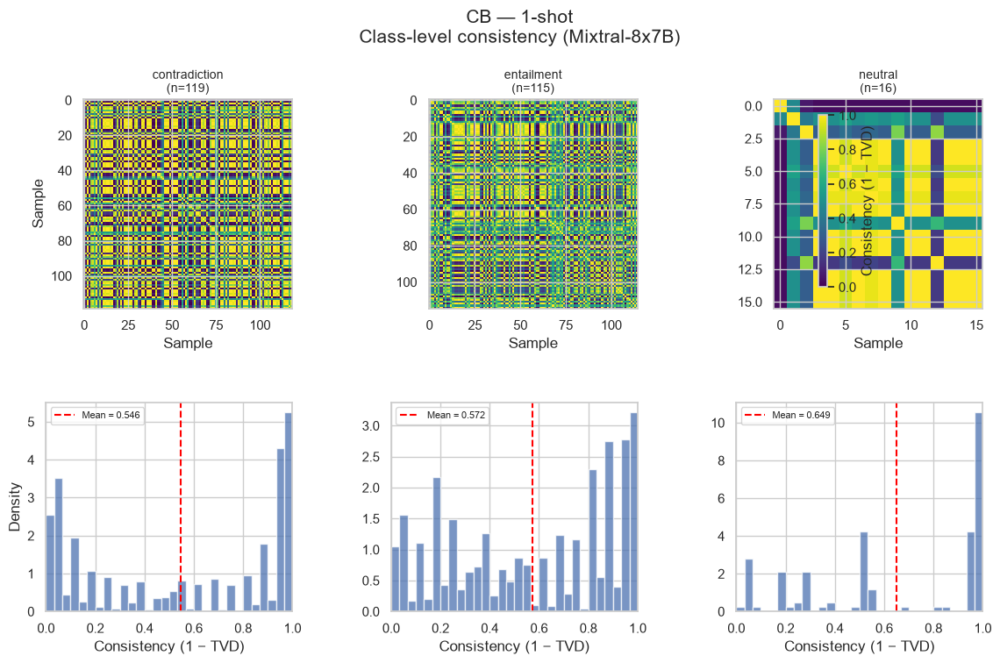

Processing RTE...


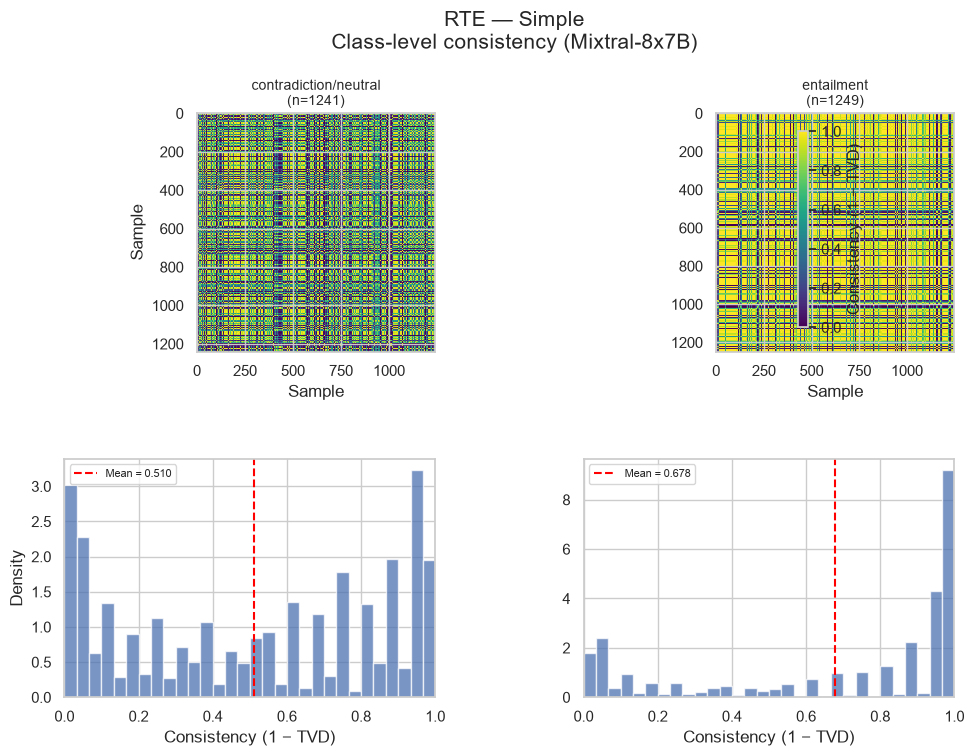

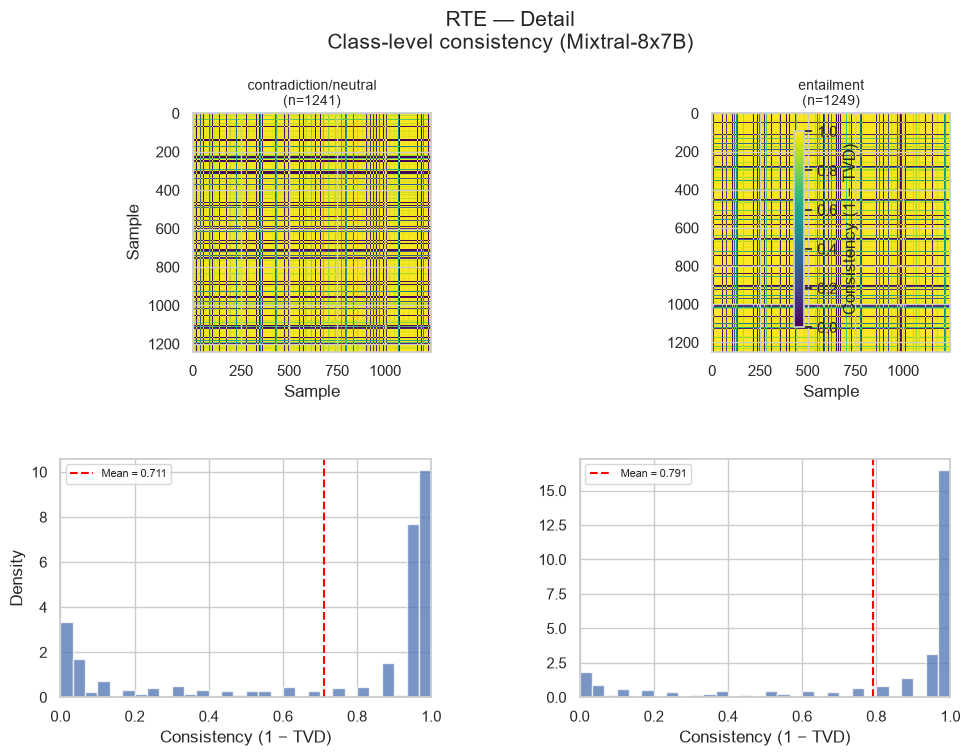

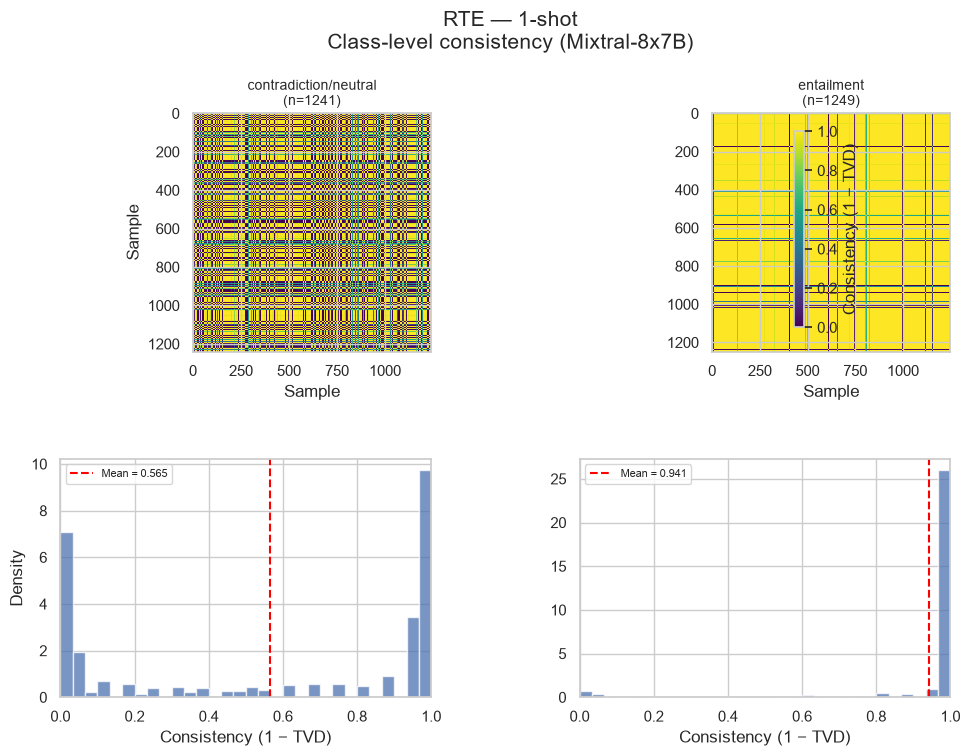

Processing DBPedia...


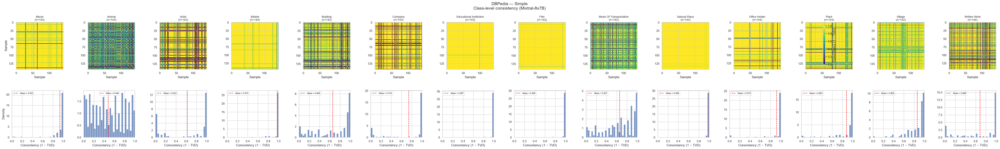

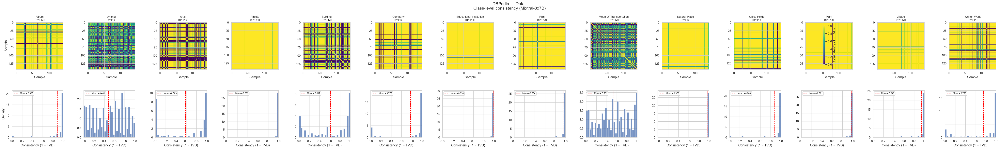

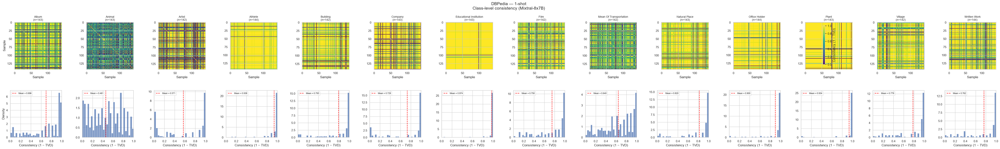

All 15 figures saved to: C:\Users\cieci\OneDrive\Dokumenty\GitHub\yellow-ducks-llm-sensitivity-consistency\mixtral8x7b-Instruct-v0.1_RESULTS\plots\consistency_by_class


In [27]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

FIGURE_DIR = PLOTS_DIR / "consistency_by_class"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

bins = np.linspace(0, 1, 31)

for dataset in dataset_order:

    print(f"Processing {dataset}...")

    for strategy, strategy_label in STRATEGIES.items():

        samples = results[dataset][strategy]

        class_distributions = {}

        for sample in samples.values():
            target = sample["target"]

            distribution = np.asarray(
                sample["distribution"],
                dtype=np.float32
            )

            class_distributions.setdefault(
                target, []
            ).append(distribution)

        class_order = sorted(class_distributions.keys())
        n_classes = len(class_order)

        fig, axes = plt.subplots(
            2,
            n_classes,
            figsize=(max(4 * n_classes, 10), 8),
            squeeze=False
        )

        for j, target in enumerate(class_order):

            P = np.asarray(
                class_distributions[target],
                dtype=np.float32
            )

            tvd = 0.5 * np.abs(
                P[:, None, :] - P[None, :, :]
            ).sum(axis=2)

            consistency = 1 - tvd


            ax_heatmap = axes[0, j]

            ax_heatmap.imshow(
                consistency,
                cmap="viridis",
                vmin=0,
                vmax=1,
                interpolation="nearest",
                rasterized=True
            )

            ax_heatmap.set_title(
                f"{target}\n(n={len(P)})",
                fontsize=10
            )

            ax_heatmap.set_xlabel("Sample")
            if j == 0:
                ax_heatmap.set_ylabel("Sample")

            ax_hist = axes[1, j]

            values = consistency.ravel()
            mean_value = values.mean()

            ax_hist.hist(
                values,
                bins=bins,
                density=True,
                alpha=0.75,
                edgecolor="white"
            )

            ax_hist.axvline(
                mean_value,
                color="red",
                linestyle="--",
                linewidth=1.5,
                label=f"Mean = {mean_value:.3f}"
            )

            ax_hist.set_xlim(0, 1)
            ax_hist.set_xlabel("Consistency (1 − TVD)")
            if j == 0:
                ax_hist.set_ylabel("Density")

            ax_hist.legend(fontsize=8)

            del tvd, consistency, values

        fig.colorbar(
            ScalarMappable(
                norm=Normalize(vmin=0, vmax=1),
                cmap="viridis"
            ),
            ax=axes[0, :].tolist(),
            label="Consistency (1 − TVD)",
            shrink=0.7,
            pad=0.02
        )

        fig.suptitle(
            f"{dataset} — {strategy_label}\n"
            "Class-level consistency (Mixtral-8x7B)",
            fontsize=15
        )

        fig.subplots_adjust(
            left=0.05,
            right=0.94,
            top=0.85,
            bottom=0.12,
            wspace=0.4,
            hspace=0.45
        )

        filename = (
            f"consistency_by_class_"
            f"{dataset.lower()}_{strategy}"
        )

        fig.savefig(
            FIGURE_DIR / f"{filename}.png",
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

print("All 15 figures saved to:", FIGURE_DIR.resolve())